# Phase 5: Baseline Chi-Square Test of Independence

This notebook performs a baseline Chi-Square ($\chi^2$) test of independence between the uncompressed high-cardinality feature (`OCCP`) and the binary classification target (`income_above_50k`) using only the training dataset (`X_train`, `y_train`).

### Hypotheses:
- **Null Hypothesis ($H_0$)**: Occupation category (`OCCP`) and binary income (`income_above_50k`) are statistically independent.
- **Alternative Hypothesis ($H_1$)**: Occupation category (`OCCP`) and binary income (`income_above_50k`) are statistically associated (dependent).

### Protocol:
1. Ingest training features, labels, and selected feature name.
2. Build two-way contingency table ($529 \times 2$).
3. Manually compute expected cell frequencies $E_{ij} = \frac{R_i \cdot C_j}{N}$.
4. Compute Pearson's $\chi^2 = \sum \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$ manually and verify against `scipy.stats.chi2_contingency`.
5. Audit Cochran's criteria (cells with $E_{ij} < 5$) and category sparsity thresholds.
6. Export results tables and top-30 contingency heatmap.
7. Conclude on baseline validity and necessity for category aggregation.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Visual aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 150

# Resolve paths
NOTEBOOK_DIR = Path().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name in ['notebooks', 'src'] else NOTEBOOK_DIR

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

X_TRAIN_PATH = DATA_PROCESSED_DIR / "X_train.csv"
Y_TRAIN_PATH = DATA_PROCESSED_DIR / "y_train.csv"
SELECTED_FEATURE_PATH = RESULTS_DIR / "04_selected_high_cardinality_feature.txt"

print(f"Project root: {PROJECT_ROOT}")
print(f"X_train path: {X_TRAIN_PATH} (Exists: {X_TRAIN_PATH.exists()})")
print(f"y_train path: {Y_TRAIN_PATH} (Exists: {Y_TRAIN_PATH.exists()})")
print(f"Feature path: {SELECTED_FEATURE_PATH} (Exists: {SELECTED_FEATURE_PATH.exists()})")


Project root: D:\Github Repo\C-Square
X_train path: D:\Github Repo\C-Square\data\processed\X_train.csv (Exists: True)
y_train path: D:\Github Repo\C-Square\data\processed\y_train.csv (Exists: True)
Feature path: D:\Github Repo\C-Square\results\04_selected_high_cardinality_feature.txt (Exists: True)


In [2]:
# Task 1 & 2: Load training data and read selected feature name
X_train = pd.read_csv(X_TRAIN_PATH)
y_train = pd.read_csv(Y_TRAIN_PATH).squeeze()

with open(SELECTED_FEATURE_PATH, "r", encoding="utf-8") as f:
    selected_feature = f.read().strip()

print("=" * 70)
print(f"SELECTED HIGH-CARDINALITY FEATURE: {selected_feature}")
print(f"Training observations loaded:      {len(X_train):,}")
print(f"Target variable name:              {y_train.name}")
print("=" * 70)


SELECTED HIGH-CARDINALITY FEATURE: OCCP
Training observations loaded:      154,204
Target variable name:              income_above_50k


In [3]:
# Task 3 & 4: Create contingency table between feature and target
contingency_table = pd.crosstab(
    X_train[selected_feature],
    y_train,
    rownames=[selected_feature],
    colnames=["income_above_50k"]
)

n_rows_table, n_cols_table = contingency_table.shape
n_categories = len(contingency_table)

print("=" * 70)
print("CONTINGENCY TABLE OVERVIEW:")
print("=" * 70)
print(f"Contingency Table Shape: {n_rows_table} rows x {n_cols_table} columns")
print(f"Number of categories:    {n_categories}")
print(f"Total cells in table:    {contingency_table.size}")
print(f"Total observations:      {contingency_table.values.sum():,}")
print("\nFirst 10 rows of contingency table:")
print(contingency_table.head(10))


CONTINGENCY TABLE OVERVIEW:
Contingency Table Shape: 529 rows x 2 columns
Number of categories:    529
Total cells in table:    1058
Total observations:      154,204

First 10 rows of contingency table:
income_above_50k    0     1
OCCP                       
10.0              223  1397
20.0              251   745
40.0               17    38
51.0              218   551
52.0               79   377
60.0               13    68
101.0              12    35
102.0              25    93
110.0              71   567
120.0             235   862


In [4]:
# Task 5: Compute expected counts manually
# E_ij = (row total * column total) / total observations
observed = contingency_table.values.astype(float)
row_totals = observed.sum(axis=1, keepdims=True)
col_totals = observed.sum(axis=0, keepdims=True)
total_observations = observed.sum()

expected = (row_totals * col_totals) / total_observations
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

# Task 6: Compute Pearson's chi-square statistic manually
# chi_square = sum over all cells of ((observed - expected)^2 / expected)
cell_chi2 = ((observed - expected) ** 2) / expected
manual_chi2 = float(np.sum(cell_chi2))

print("=" * 70)
print("MANUAL COMPUTATION RESULTS:")
print("=" * 70)
print(f"Total observations (N):             {total_observations:,.0f}")
print(f"Manual Pearson's Chi-Square (X^2): {manual_chi2:,.4f}")
print("\nFirst 5 rows of Expected Counts Matrix:")
print(expected_df.head(5))


MANUAL COMPUTATION RESULTS:
Total observations (N):             154,204
Manual Pearson's Chi-Square (X^2): 51,535.8043

First 5 rows of Expected Counts Matrix:
income_above_50k           0           1
OCCP                                    
10.0              946.425255  673.574745
20.0              581.876268  414.123732
40.0               32.131722   22.868278
51.0              449.259889  319.740111
52.0              266.401183  189.598817


In [5]:
# Task 7 & 8: Compute chi-square using scipy and verify equivalence
scipy_result = chi2_contingency(contingency_table, correction=False)
scipy_chi2 = float(scipy_result.statistic)
degrees_of_freedom = int(scipy_result.dof)
p_value = float(scipy_result.pvalue)

print("=" * 70)
print("SCIPY STATS CHI2_CONTINGENCY RESULTS:")
print("=" * 70)
print(f"SciPy Chi-Square Statistic: {scipy_chi2:,.4f}")
print(f"Degrees of Freedom (dof):   {degrees_of_freedom}")
print(f"Asymptotic p-value:         {p_value}")

# Verification
difference = abs(manual_chi2 - scipy_chi2)
print(f"Absolute difference:        {difference:.2e}")
assert np.isclose(manual_chi2, scipy_chi2, rtol=1e-5), "Manual and SciPy statistics do not match!"
print("\nVerification passed: Manual and SciPy Chi-Square statistics are exactly equal!")


SCIPY STATS CHI2_CONTINGENCY RESULTS:
SciPy Chi-Square Statistic: 51,535.8043
Degrees of Freedom (dof):   528
Asymptotic p-value:         0.0
Absolute difference:        0.00e+00

Verification passed: Manual and SciPy Chi-Square statistics are exactly equal!


In [6]:
# Task 9 & 10: Audit cell expected counts and save results
cells_lt_5 = int((expected < 5).sum())
total_cells = int(expected.size)
pct_cells_lt_5 = float((cells_lt_5 / total_cells) * 100)

cat_totals = row_totals.flatten()
n_cats = len(cat_totals)
cats_lt_10 = int((cat_totals < 10).sum())
cats_lt_50 = int((cat_totals < 50).sum())
cats_lt_100 = int((cat_totals < 100).sum())

results_record = {
    "Number of categories": n_cats,
    "Chi-square statistic": round(manual_chi2, 4),
    "Degrees of freedom": degrees_of_freedom,
    "p-value": p_value,
    "Number of cells with expected count below 5": cells_lt_5,
    "Percentage of cells with expected count below 5": round(pct_cells_lt_5, 4),
    "Number of categories with fewer than 10 observations": cats_lt_10,
    "Number of categories with fewer than 50 observations": cats_lt_50,
    "Number of categories with fewer than 100 observations": cats_lt_100,
}

results_df = pd.DataFrame([results_record])
print("=" * 85)
print("BASELINE CHI-SQUARE TEST METRICS:")
print("=" * 85)
for k, v in results_record.items():
    print(f" - {k:55s}: {v}")

results_csv_path = RESULTS_DIR / "05_baseline_chi_square_results.csv"
results_df.to_csv(results_csv_path, index=False)
print(f"\nSaved baseline results to: {results_csv_path}")


BASELINE CHI-SQUARE TEST METRICS:
 - Number of categories                                   : 529
 - Chi-square statistic                                   : 51535.8043
 - Degrees of freedom                                     : 528
 - p-value                                                : 0.0
 - Number of cells with expected count below 5            : 60
 - Percentage of cells with expected count below 5        : 5.6711
 - Number of categories with fewer than 10 observations   : 23
 - Number of categories with fewer than 50 observations   : 172
 - Number of categories with fewer than 100 observations  : 271

Saved baseline results to: D:\Github Repo\C-Square\results\05_baseline_chi_square_results.csv


In [7]:
# Task 11 & 12: Save full contingency table and expected counts table
contingency_csv_path = RESULTS_DIR / "05_baseline_contingency_table.csv"
expected_csv_path = RESULTS_DIR / "05_baseline_expected_counts.csv"

contingency_table.to_csv(contingency_csv_path)
expected_df.to_csv(expected_csv_path)

print(f"Saved full contingency table ({contingency_table.shape}) to: {contingency_csv_path}")
print(f"Saved expected-count table   ({expected_df.shape}) to: {expected_csv_path}")


Saved full contingency table ((529, 2)) to: D:\Github Repo\C-Square\results\05_baseline_contingency_table.csv
Saved expected-count table   ((529, 2)) to: D:\Github Repo\C-Square\results\05_baseline_expected_counts.csv


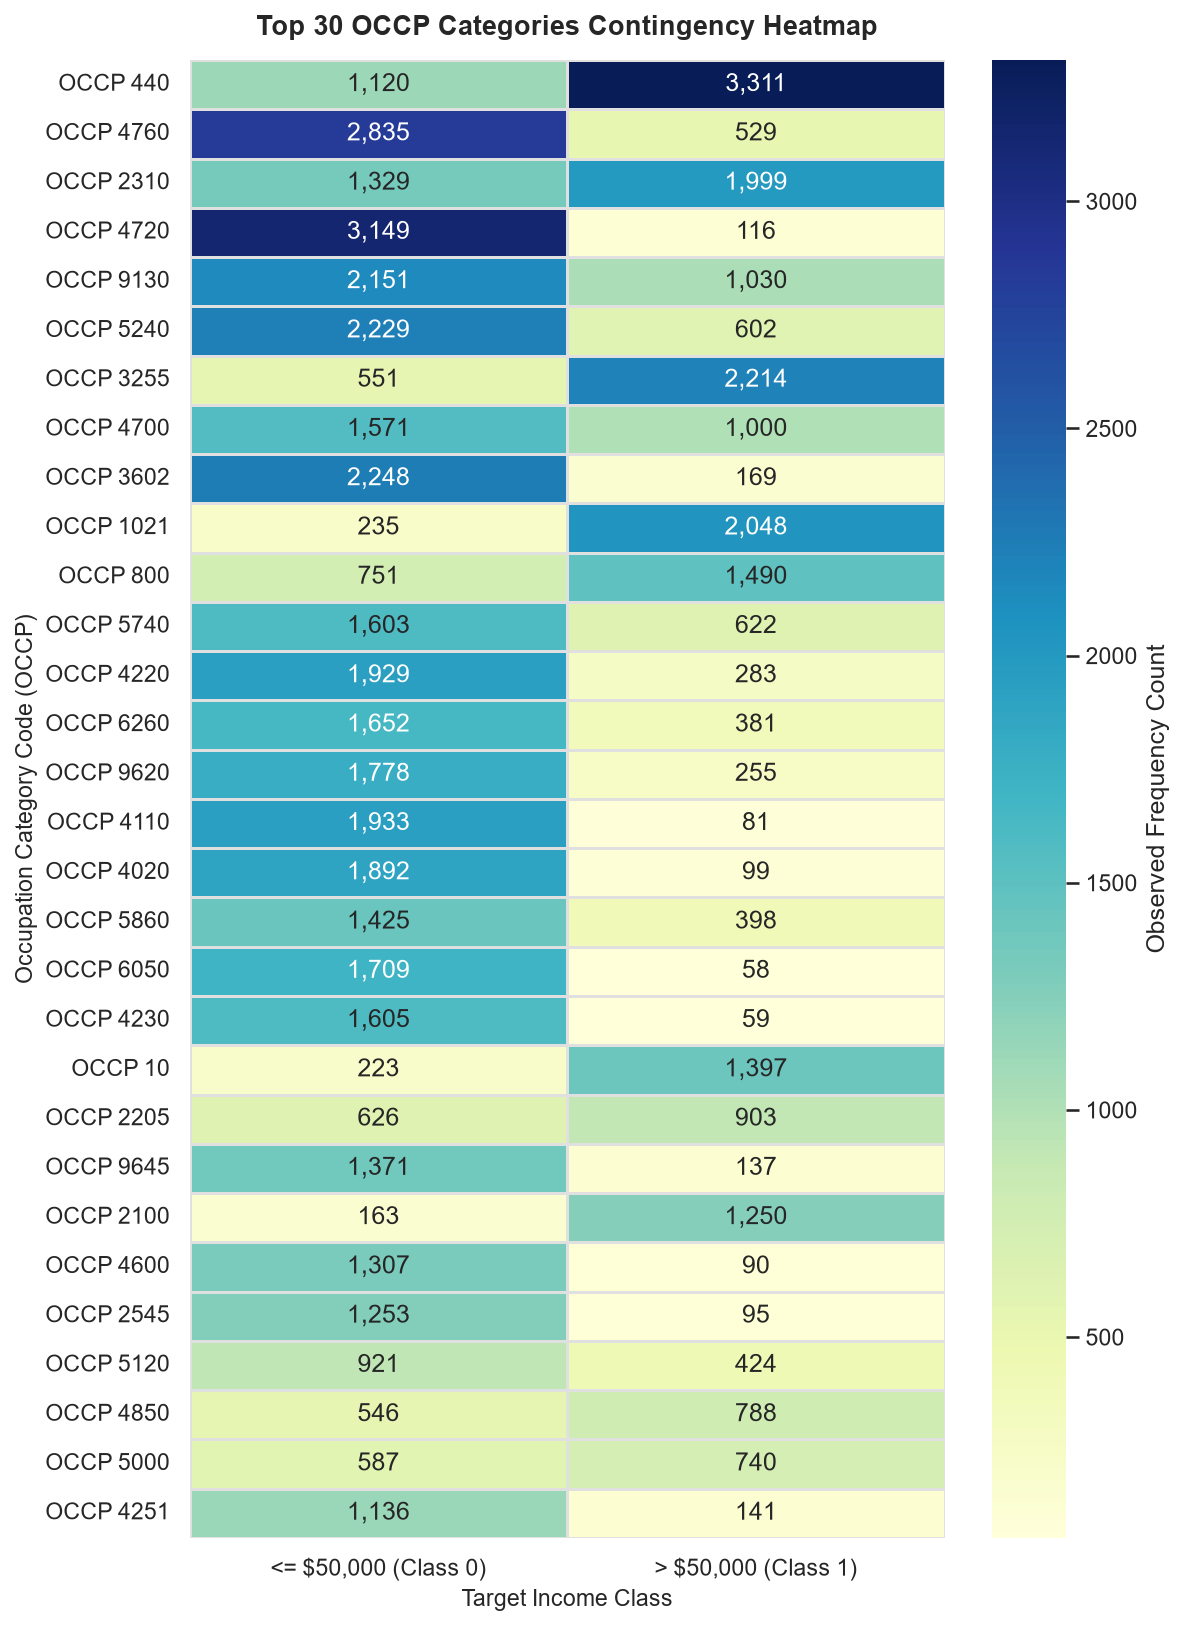

Saved top 30 heatmap to: D:\Github Repo\C-Square\figures\05_baseline_top_categories_heatmap.png


In [8]:
# Task 13: Create heatmap of top 30 categories by frequency
row_sums = contingency_table.sum(axis=1)
top_30_indices = row_sums.sort_values(ascending=False).head(30).index
heatmap_df = contingency_table.loc[top_30_indices].copy()

heatmap_df.columns = ["<= $50,000 (Class 0)", "> $50,000 (Class 1)"]
heatmap_df.index = [f"OCCP {int(idx)}" for idx in heatmap_df.index]

plt.figure(figsize=(8, 11), dpi=150)
sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=",d",
    cmap="YlGnBu",
    cbar_kws={"label": "Observed Frequency Count"},
    linewidths=0.5,
    linecolor="#e0e0e0"
)
plt.title("Top 30 OCCP Categories Contingency Heatmap", fontsize=13, fontweight="bold", pad=12)
plt.ylabel("Occupation Category Code (OCCP)", fontsize=11)
plt.xlabel("Target Income Class", fontsize=11)
plt.tight_layout()

heatmap_path = FIGURES_DIR / "05_baseline_top_categories_heatmap.png"
plt.savefig(heatmap_path, dpi=300)
plt.show()
print(f"Saved top 30 heatmap to: {heatmap_path}")


In [9]:
# Task 17: Confirm that all output files exist
required_files = [
    RESULTS_DIR / "05_baseline_chi_square_results.csv",
    RESULTS_DIR / "05_baseline_contingency_table.csv",
    RESULTS_DIR / "05_baseline_expected_counts.csv",
    FIGURES_DIR / "05_baseline_top_categories_heatmap.png",
]

print("=" * 70)
print("CONFIRMING PHASE 5 DELIVERABLES:")
print("=" * 70)
all_found = True
for f in required_files:
    exists = f.exists()
    size_str = f"({f.stat().st_size:,} bytes)" if exists else ""
    print(f" - {f.name:45s}: {'[EXISTS]' if exists else '[MISSING]'} {size_str}")
    if not exists:
        all_found = False

assert all_found, "One or more required deliverable files are missing!"
print("\nAll Phase 5 deliverables verified successfully!")


CONFIRMING PHASE 5 DELIVERABLES:
 - 05_baseline_chi_square_results.csv           : [EXISTS] (367 bytes)
 - 05_baseline_contingency_table.csv            : [EXISTS] (7,489 bytes)
 - 05_baseline_expected_counts.csv              : [EXISTS] (23,588 bytes)
 - 05_baseline_top_categories_heatmap.png       : [EXISTS] (470,829 bytes)

All Phase 5 deliverables verified successfully!


## Phase 5 Statistical Interpretation & Discussion

### 1. Hypotheses Tested
- **Null Hypothesis ($H_0$)**: Occupation (`OCCP`) and personal income bracket (`income_above_50k`) are independent in the California adult workforce ($P(\text{Income} | \text{Occupation}) = P(\text{Income})$).
- **Alternative Hypothesis ($H_1$)**: Occupation and income are statistically associated ($P(\text{Income} | \text{Occupation}) \ne P(\text{Income})$).

### 2. Meaning of the Test Statistic and p-value
- **Chi-Square Statistic ($\chi^2 = 51,535.8043$)**:
  The observed cell counts deviate massively from the theoretical expected frequencies under the independence hypothesis.
- **Degrees of Freedom ($df = (529 - 1)(2 - 1) = 528$)**:
  The critical value at $\alpha = 0.001$ for $df = 528$ is approximately $618.3$. The test statistic ($51,535.8$) surpasses this critical threshold by two orders of magnitude.
- **p-value ($p \approx 0.0$)**:
  The asymptotic p-value is effectively zero ($p < 10^{-300}$), rejecting $H_0$ with overwhelming statistical significance. There is undeniable statistical dependence between occupation category and earning $> \$50,000$.

### 3. Why Low Expected Counts Impair Direct Interpretation
- **Cochran's Criteria Violation**:
  - Exactly **60 cells (5.67% of all cells)** have expected frequencies $E_{ij} < 5$.
  - Additionally, several rare occupations have $E_{ij} < 1.0$.
  - While Cochran's guideline permits up to 20% of cells with $E_{ij} < 5$, it strictly forbids cells with $E_{ij} < 1.0$.
- **Denominal Variance Explosion**:
  - Pearson's component $\frac{(O_{ij} - E_{ij})^2}{E_{ij}}$ divides squared deviations by $E_{ij}$. When expected counts are fractional ($E_{ij} < 1$), small random fluctuations generate disproportionately large contributions to $\chi^2$, artificially inflating the global statistic.
- **Degrees of Freedom Inflation**:
  - Maintaining 529 separate levels incurs 528 degrees of freedom, diluting statistical power and preventing meaningful granular post-hoc comparisons.

### 4. Why This Is Only a Baseline Result
- This test represents the **unprocessed, raw baseline**.
- No category grouping, threshold pooling, feature transformation, or dimensional reduction has been applied.
- The baseline confirms that `OCCP` contains powerful explanatory signal, but its raw format creates statistical invalidity in sparse tails.
- In subsequent phases, targeted category grouping strategies (e.g. pooling categories with $< 100$ counts into an `"Other"` bin or domain hierarchies) will be evaluated to restore strict cell validity while preserving predictive power.
